# Scaling du rapport avec le nouveau CMIIC

Les huit algorithmes du rapport cbnsl_benchmark_report (CSV unifiés de `remetrics/`, CPC et CMIIC en version agrum3) et le nouveau CMIIC (run du 29 octobre 2026, mode Analytic, split, seuil μ_n + z σ_tot, α = 0.05). Mêmes graphes et mêmes jeux de données (seed 42, 30 graphes).

Mêmes figures que la section scaling du rapport, une par cellule : temps d'exécution, puis SHD, F1 et TPR sur les CPDAG, puis sur les squelettes. Moyenne plus ou moins erreur standard sur les 30 graphes.

**Attention.** Ce run change deux choses à la fois par rapport à CMIIC : le seuil analytique sur les tests à deux points, et la pénalité à trois points mise à 0 au lieu de −α, ce qui oriente presque toutes les arêtes. Le gain sur les CPDAG vient en grande partie du second changement. Voir positionnement_et_priorites.md, section 6, dans cmiic_wip.

In [1]:
import sys; sys.path.insert(0, "../../..")
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from experiments.scaling.io import load_results

# Police façon LaTeX, comme les figures du rapport cbnsl_benchmark_report
matplotlib.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
})

# Les huit algorithmes du rapport viennent des CSV unifiés de remetrics/,
# CPC et CMIIC en version agrum3 (latex_report_plots.ipynb). Le nouveau CMIIC vient du run d'octobre.
NEW = {
    "sem_gaussian": "2026-10-29_18h55_sem_gaussian_3pt_sans_penalite",
    "sem_laplace": "2026-10-29_20h19_sem_laplace_3pt_sans_penalite",
    "cbn_unif_gauss": "2026-10-29_21h38_cbn_unif_gauss_3pt_sans_penalite",
    "cbn_exp_clayton": "2026-10-30_00h46_cbn_exp_clayton_3pt_sans_penalite",
    "cbn_unif_mixture": "2026-10-30_03h53_cbn_unif_mixture_3pt_sans_penalite"
}

# Même ordre et mêmes couleurs que les figures du rapport, le nouveau CMIIC en plus
ALGO_ORDER = ["CPC", "CMIIC", "MIIC", "GHC+BDeu", "NOTEARS", "NOTEARS Disc.", "LiNGAM", "DAGMA", "nouveau CMIIC"]
ALGO_COLORS = {algo: sns.color_palette()[i] for i, algo in enumerate(ALGO_ORDER[:-1])}
ALGO_COLORS["nouveau CMIIC"] = "tab:cyan"

def load_all(gen):
    """Les huit algorithmes du rapport et le nouveau CMIIC, pour un générateur."""
    report = pd.read_csv(f"../remetrics/{gen}.csv")
    report = report[~report.algo.isin(["CPC", "CMIIC"]) | (report.version == "agrum3")]
    new = load_results(f"{NEW[gen]}/results.csv")
    new["algo"] = "nouveau CMIIC"
    return pd.concat([report, new], ignore_index=True)

def plot(df, n_vars, y, ylabel):
    """Une figure, moyenne +/- erreur standard sur les graphes, une courbe par algorithme."""
    data = df[df.n_vars == n_vars]
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.lineplot(
        data=data, x="n_samples", y=y,
        hue="algo", hue_order=ALGO_ORDER, palette=ALGO_COLORS,
        errorbar="se", marker="o", ax=ax,
    )
    ax.set_xlabel("Number of samples")
    ax.set_ylabel(ylabel)
    ax.legend(title=None, frameon=True)
    fig.tight_layout()
    plt.show()

# SEM Gaussian

In [2]:
df = load_all("sem_gaussian")

## 10 variables

### Temps d'exécution

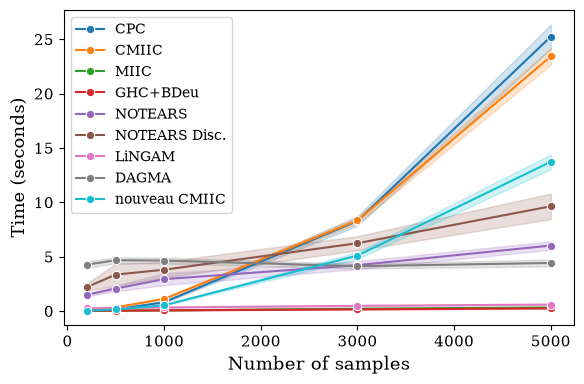

In [3]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

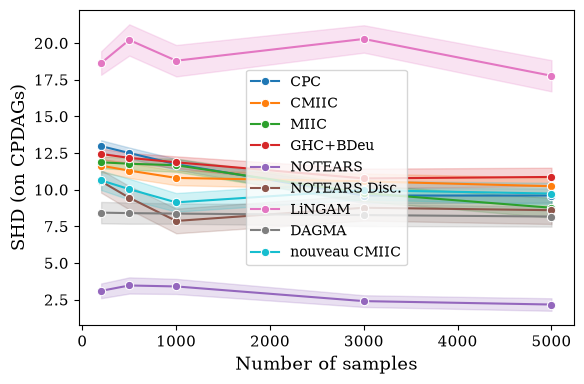

In [4]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

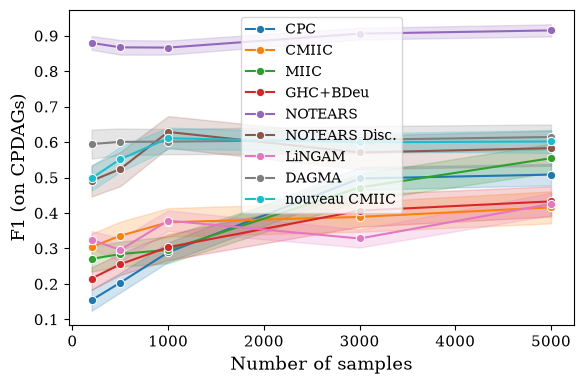

In [5]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

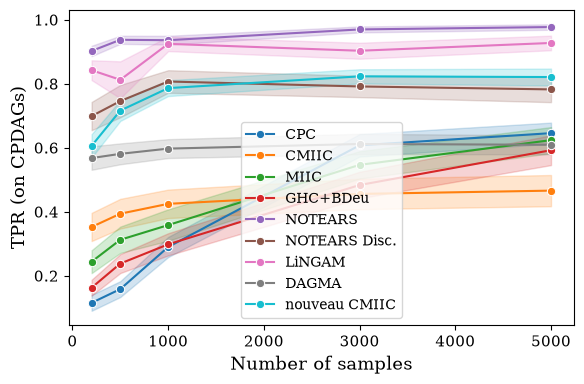

In [6]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

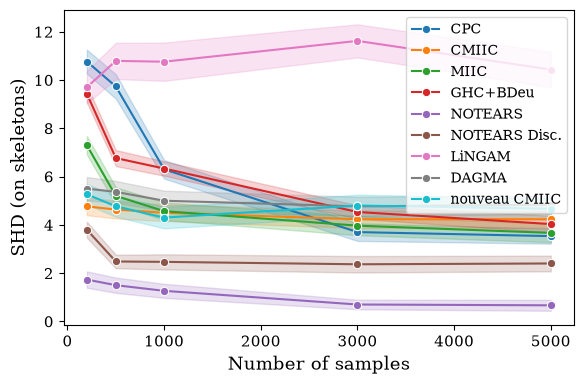

In [7]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

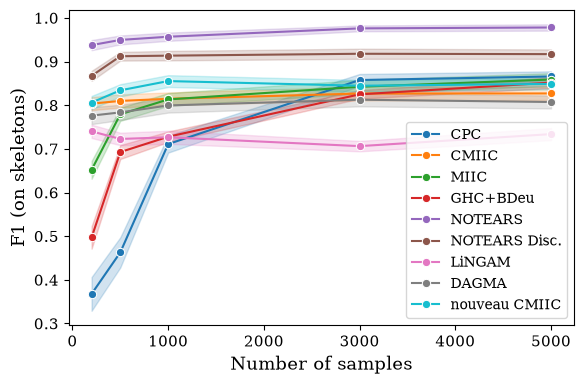

In [8]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

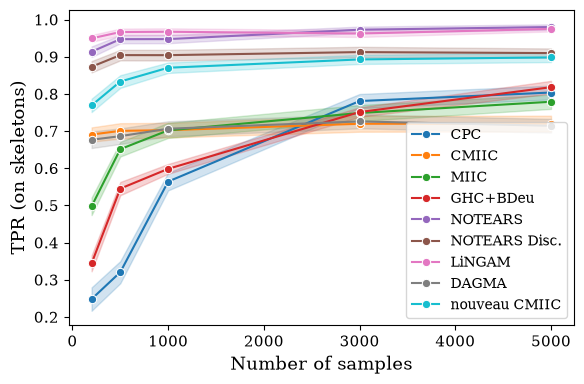

In [9]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

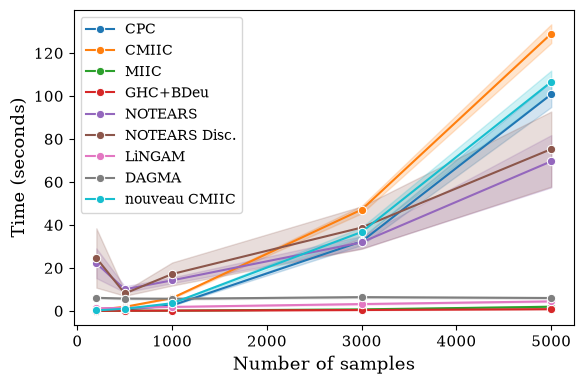

In [10]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

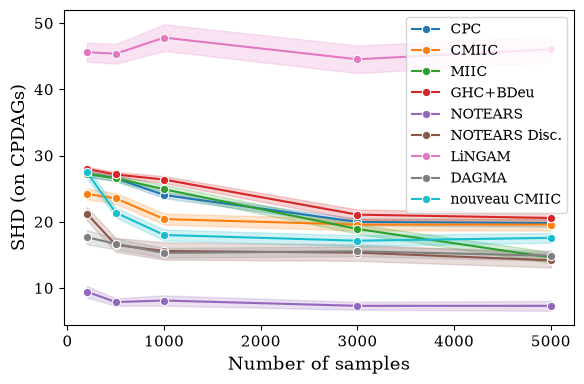

In [11]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

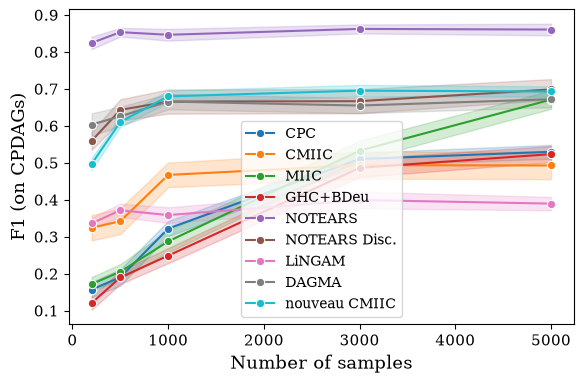

In [12]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

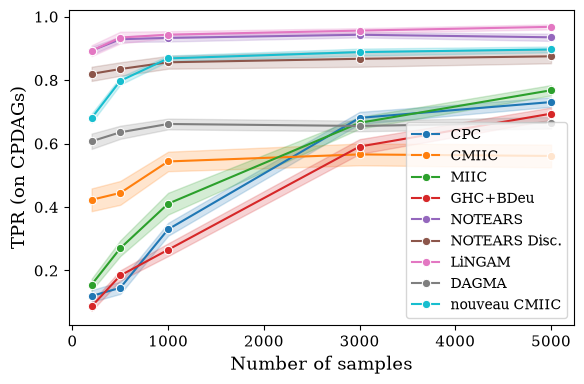

In [13]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

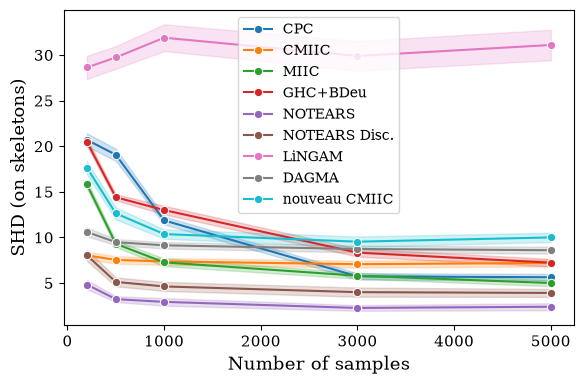

In [14]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

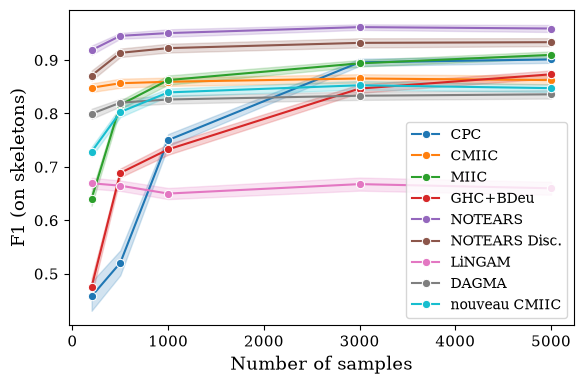

In [15]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

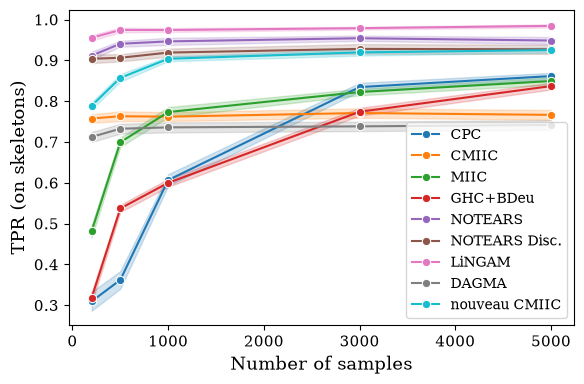

In [16]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# SEM Laplace

In [17]:
df = load_all("sem_laplace")

## 10 variables

### Temps d'exécution

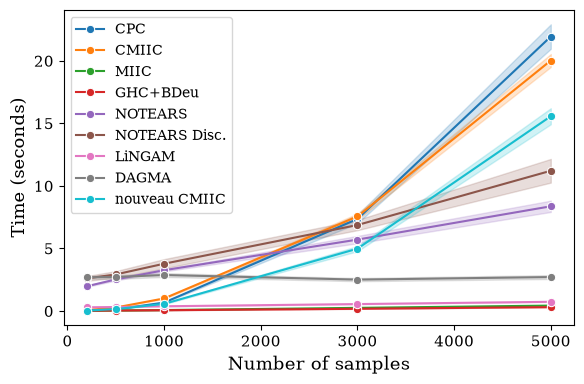

In [18]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

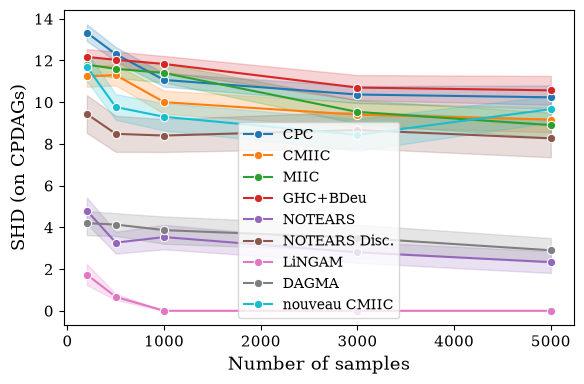

In [19]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

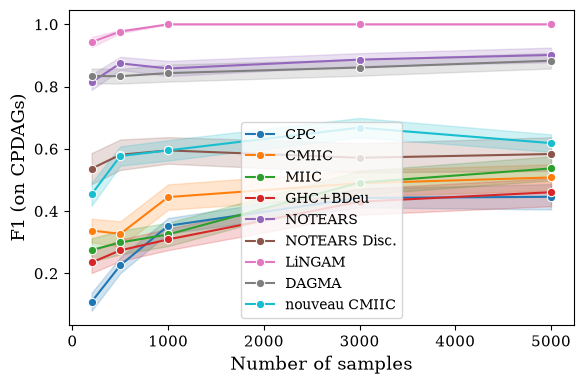

In [20]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

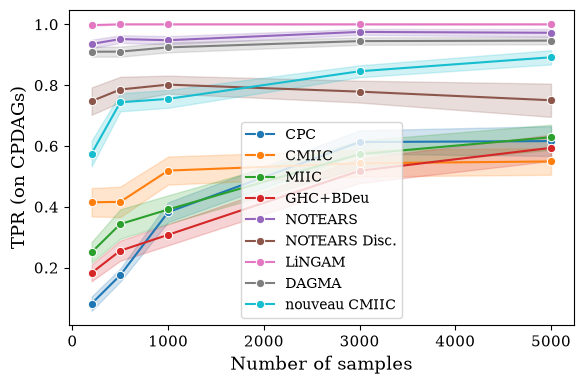

In [21]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

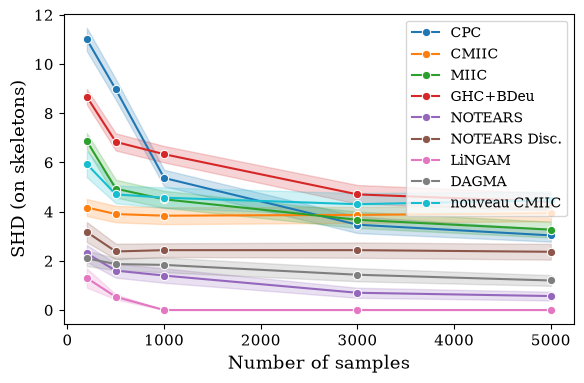

In [22]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

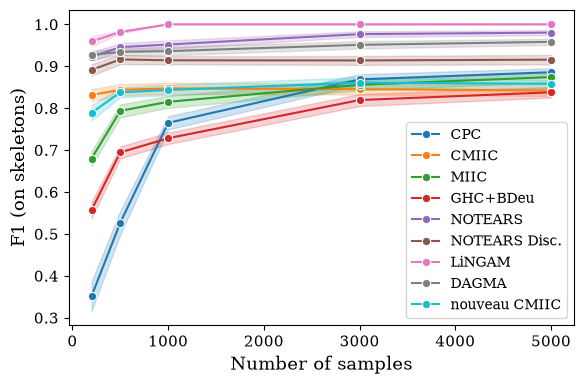

In [23]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

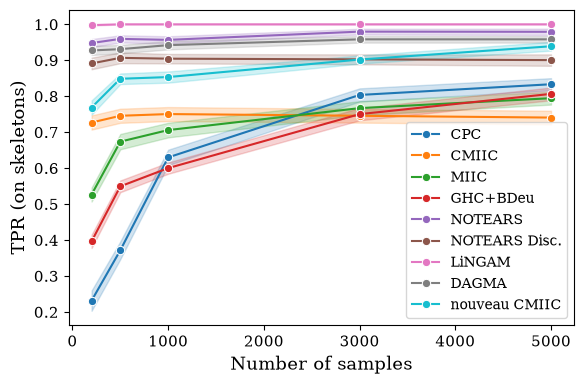

In [24]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

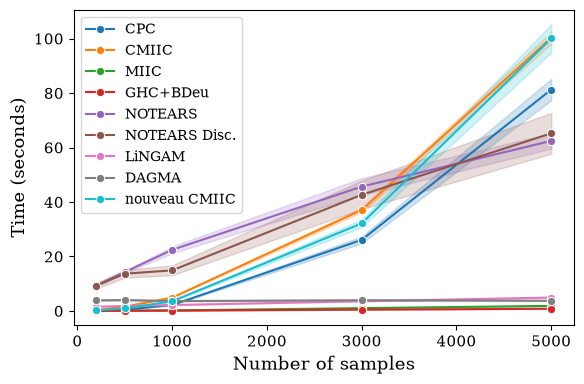

In [25]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

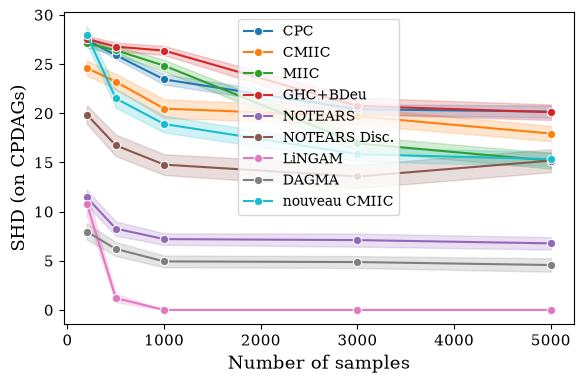

In [26]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

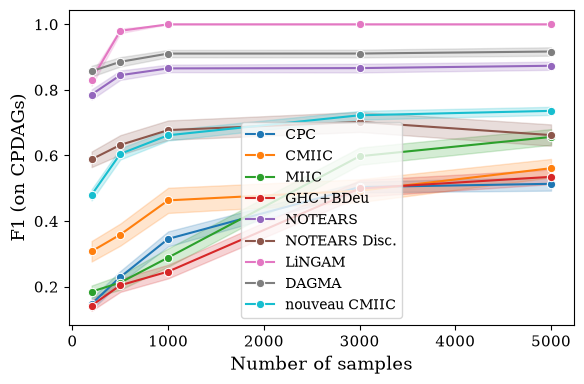

In [27]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

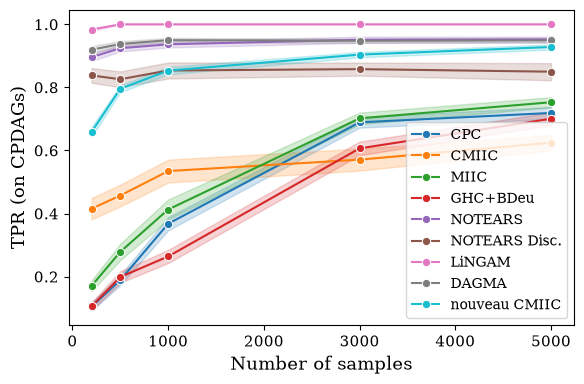

In [28]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

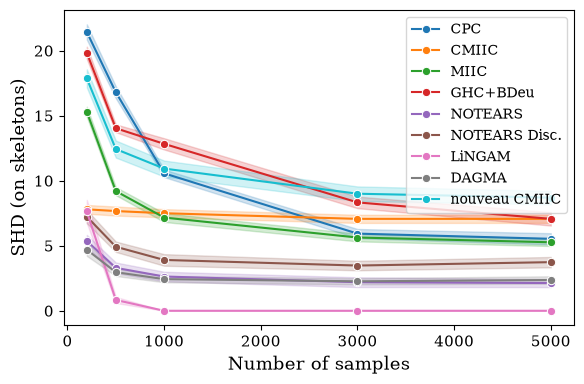

In [29]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

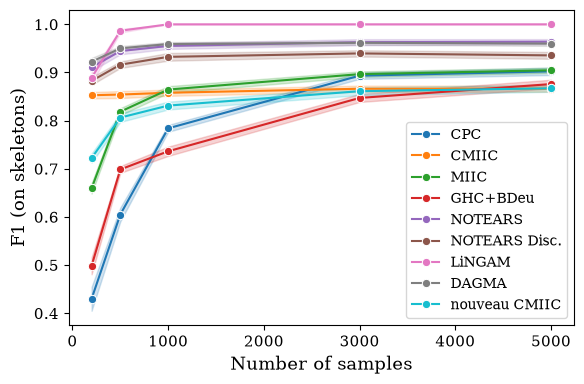

In [30]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

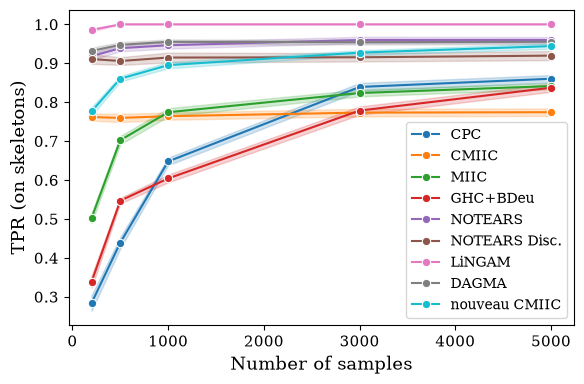

In [31]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# CBN Uniform/Gaussian

In [32]:
df = load_all("cbn_unif_gauss")

## 10 variables

### Temps d'exécution

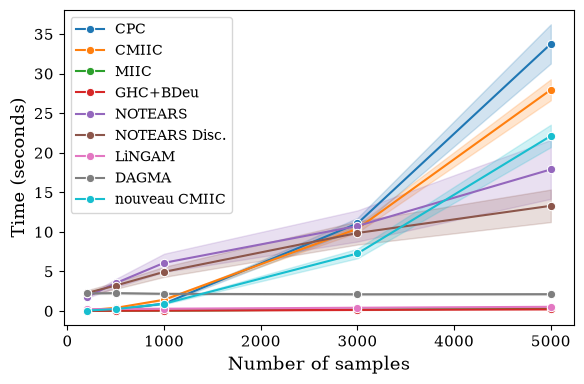

In [33]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

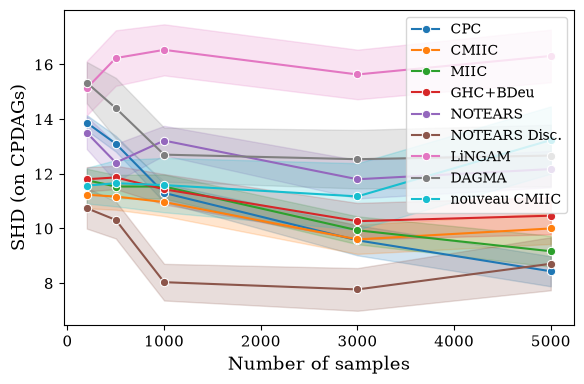

In [34]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

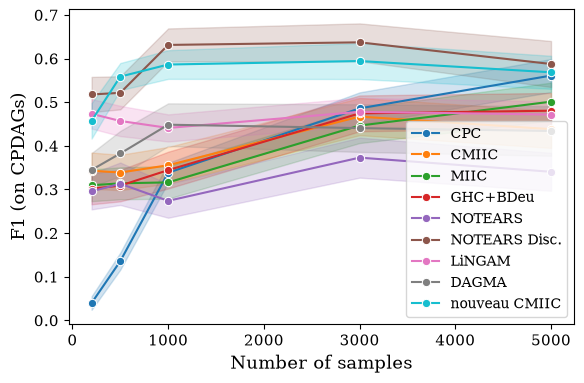

In [35]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

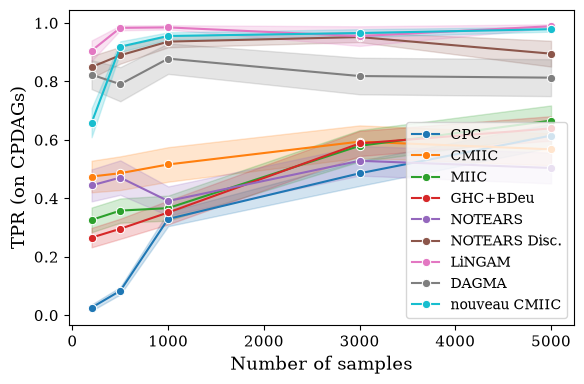

In [36]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

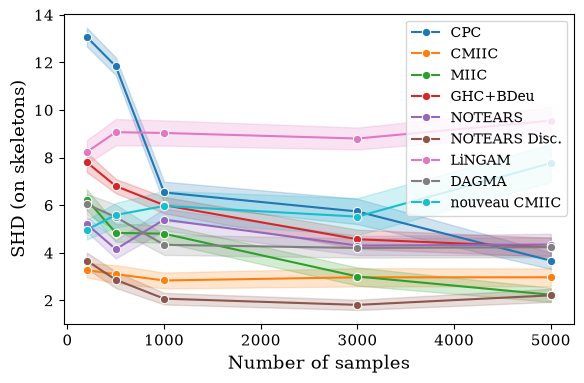

In [37]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

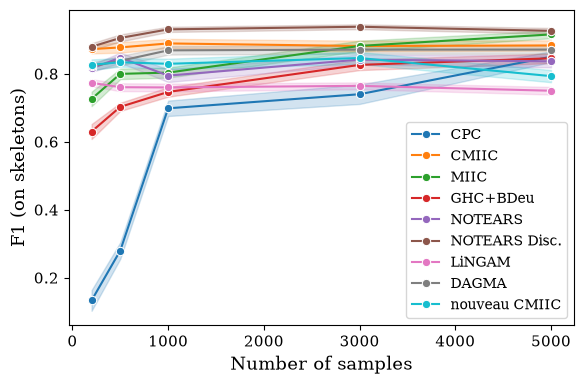

In [38]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

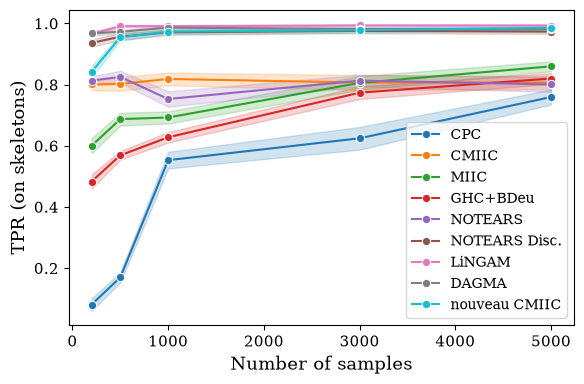

In [39]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

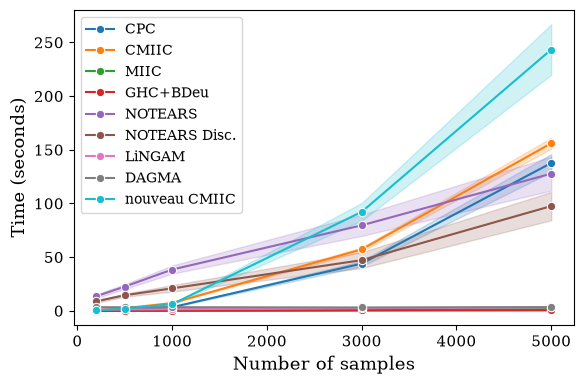

In [40]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

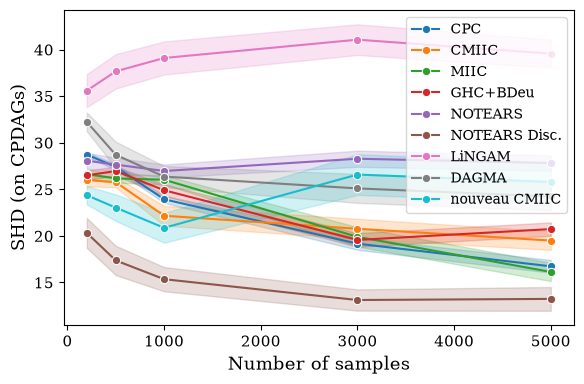

In [41]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

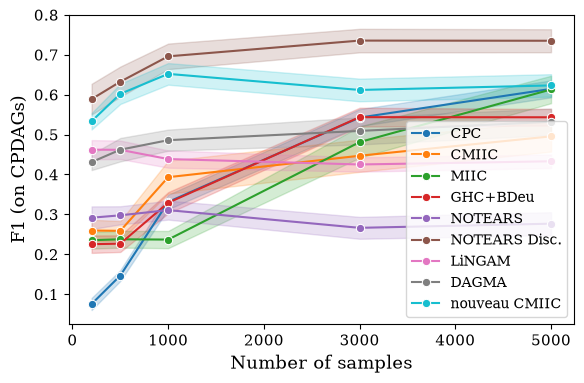

In [42]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

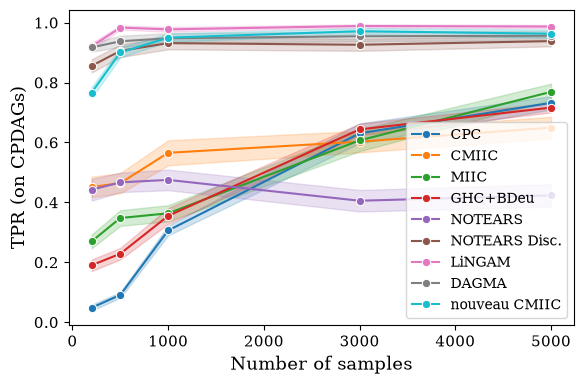

In [43]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

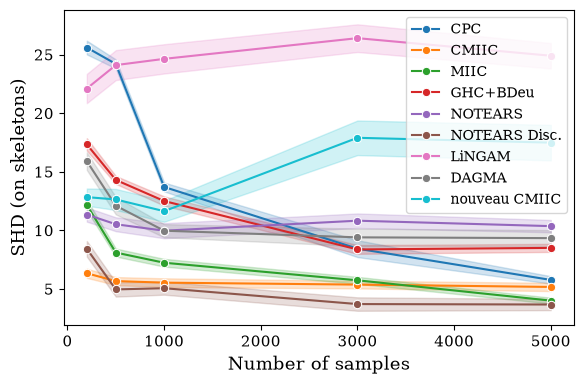

In [44]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

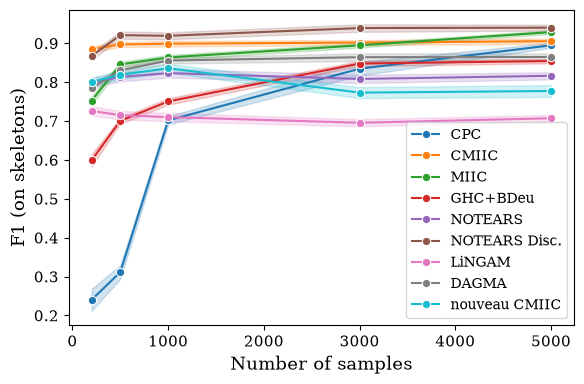

In [45]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

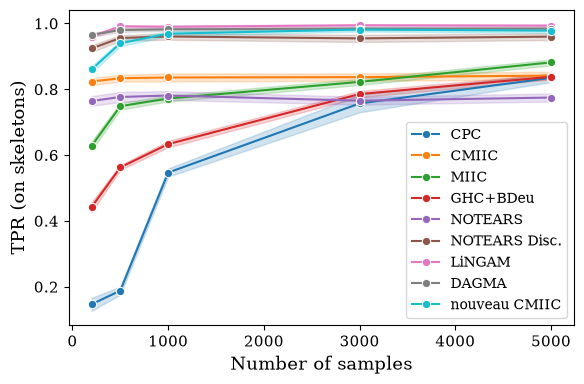

In [46]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# CBN Exponential/Clayton

In [47]:
df = load_all("cbn_exp_clayton")

## 10 variables

### Temps d'exécution

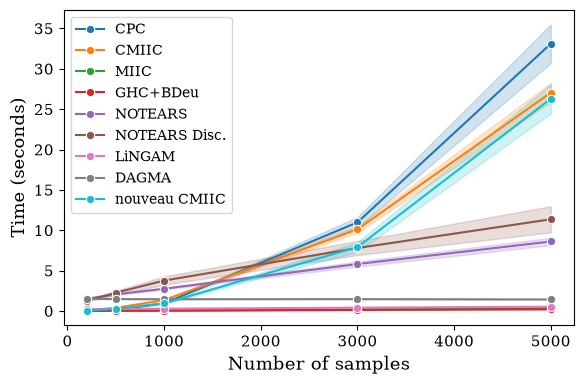

In [48]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

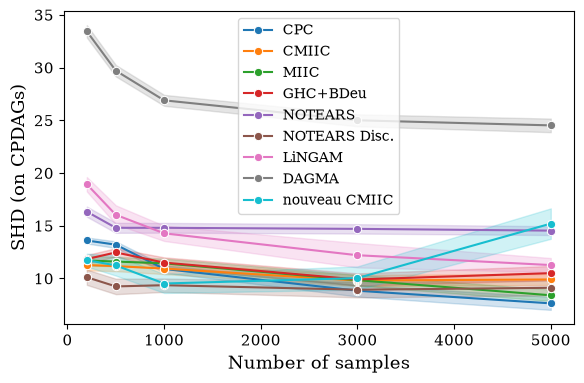

In [49]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

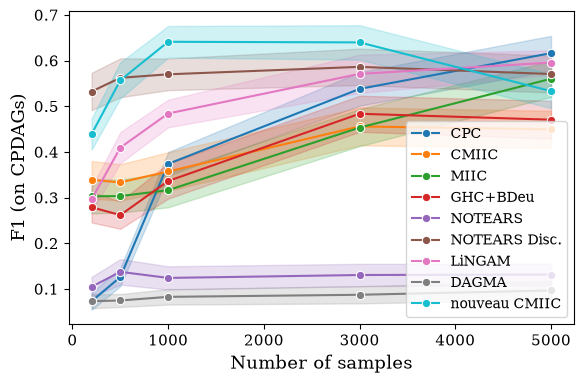

In [50]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

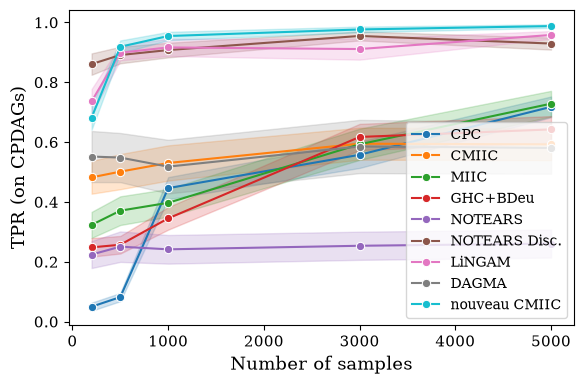

In [51]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

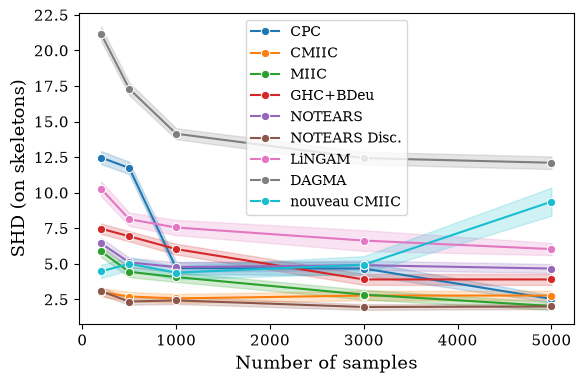

In [52]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

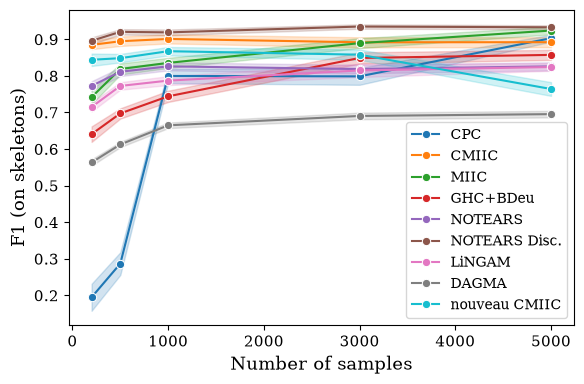

In [53]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

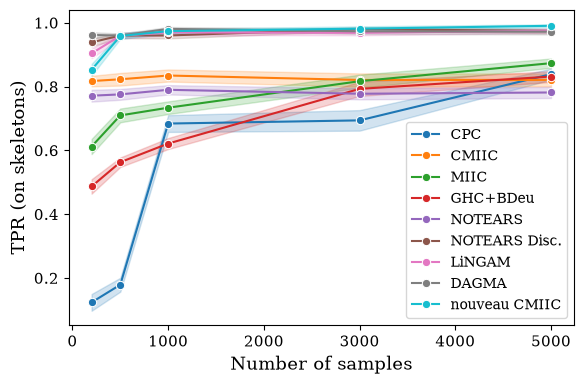

In [54]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

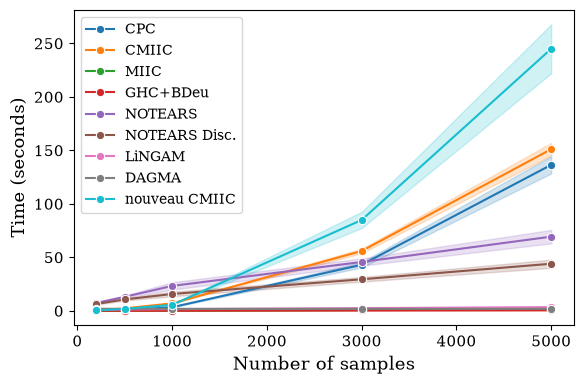

In [55]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

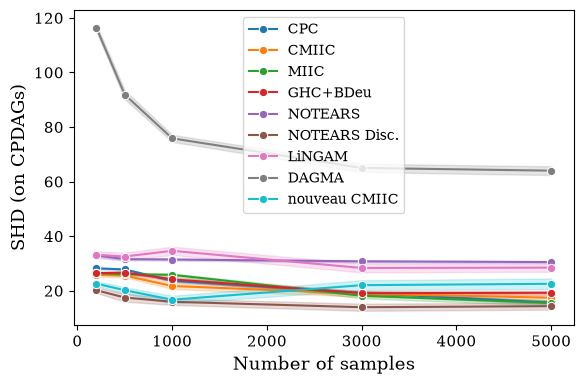

In [56]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

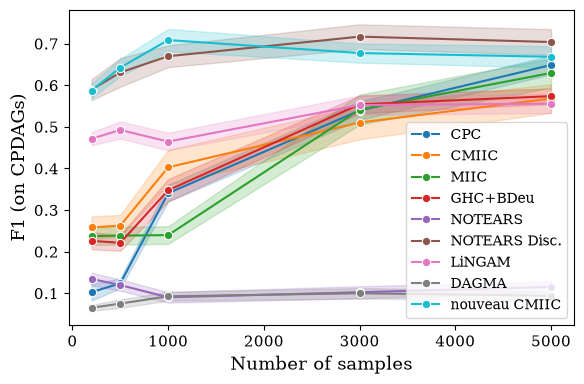

In [57]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

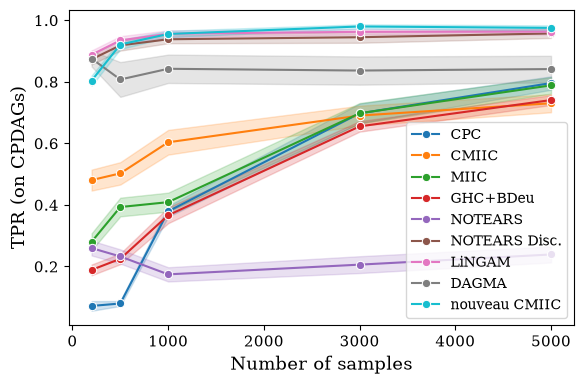

In [58]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

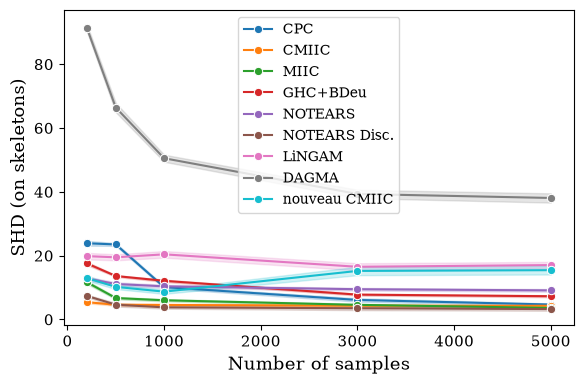

In [59]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

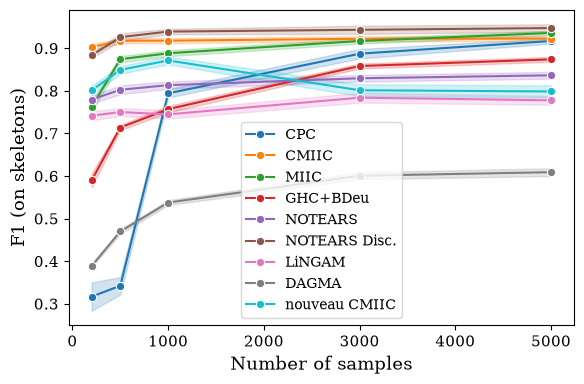

In [60]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

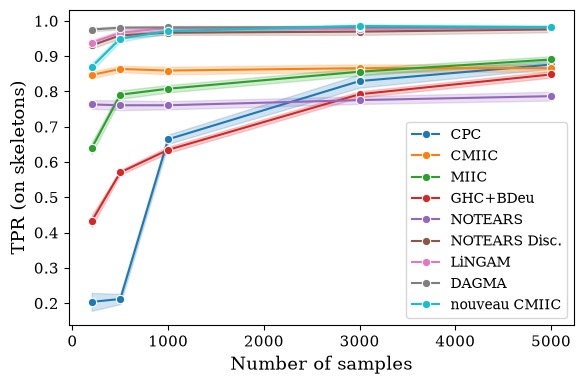

In [61]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")

# CBN Uniform/Mixture

In [62]:
df = load_all("cbn_unif_mixture")

## 10 variables

### Temps d'exécution

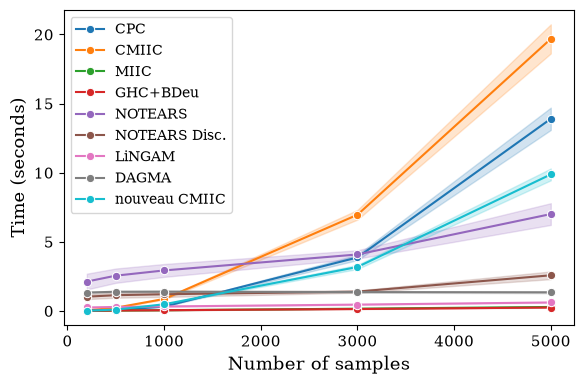

In [63]:
plot(df, 10, "time_s", "Time (seconds)")

### Sur les CPDAG

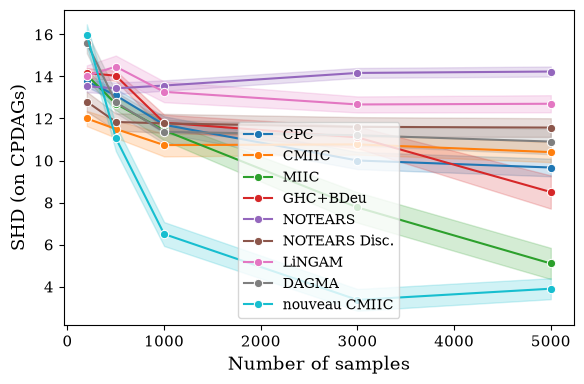

In [64]:
plot(df, 10, "SHD", "SHD (on CPDAGs)")

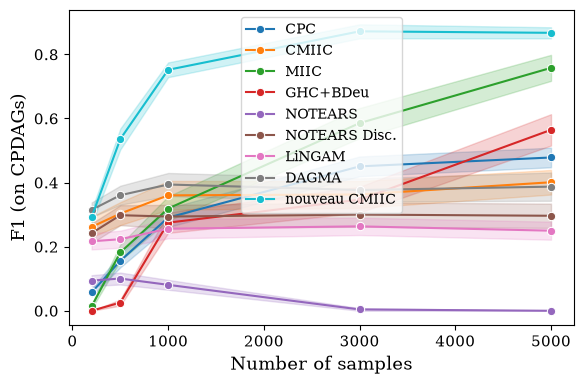

In [65]:
plot(df, 10, "F1-Score", "F1 (on CPDAGs)")

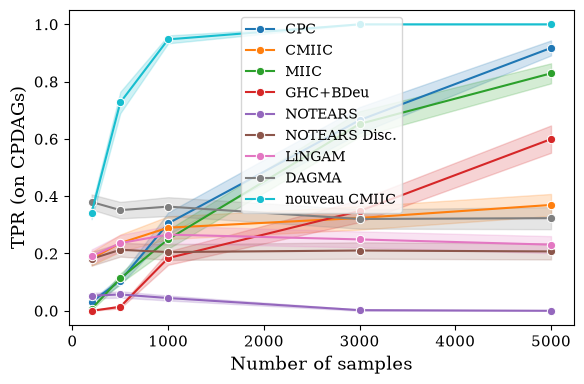

In [66]:
plot(df, 10, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

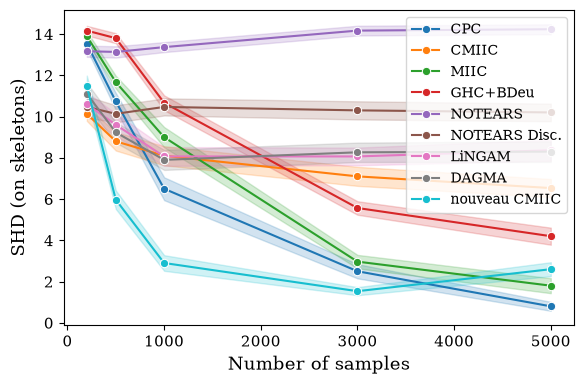

In [67]:
plot(df, 10, "SHD_skeleton", "SHD (on skeletons)")

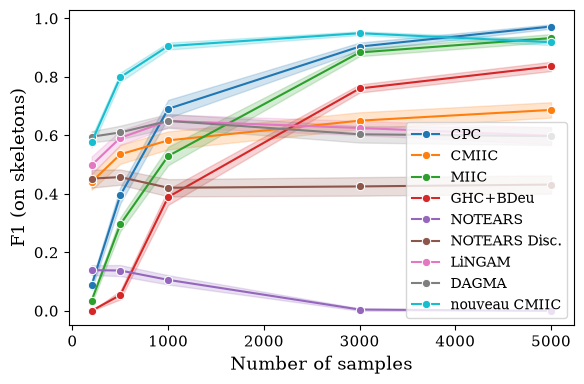

In [68]:
plot(df, 10, "F1-Score_skeleton", "F1 (on skeletons)")

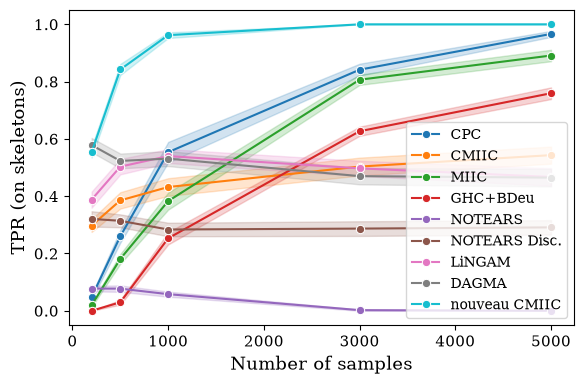

In [69]:
plot(df, 10, "TPR_skeleton", "TPR (on skeletons)")

## 20 variables

### Temps d'exécution

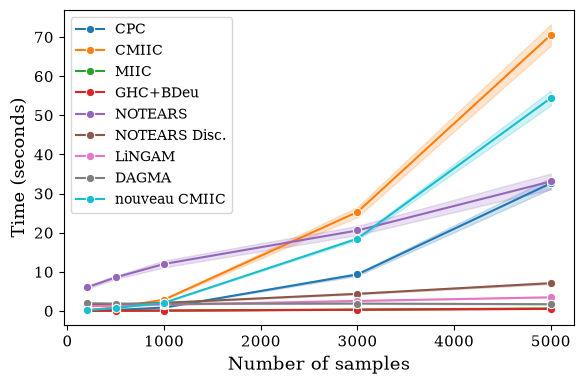

In [70]:
plot(df, 20, "time_s", "Time (seconds)")

### Sur les CPDAG

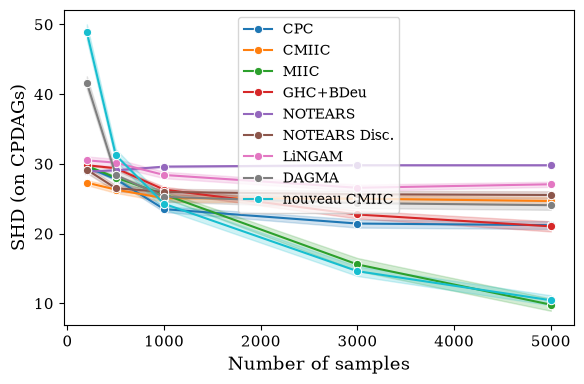

In [71]:
plot(df, 20, "SHD", "SHD (on CPDAGs)")

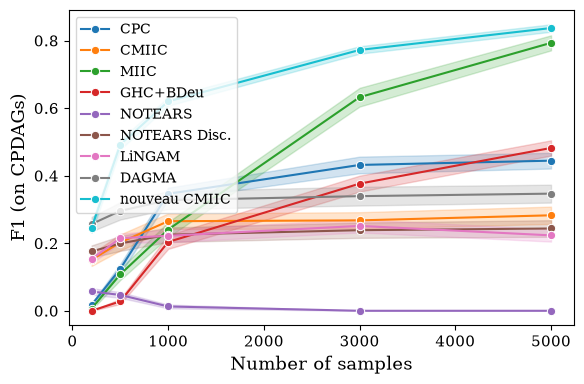

In [72]:
plot(df, 20, "F1-Score", "F1 (on CPDAGs)")

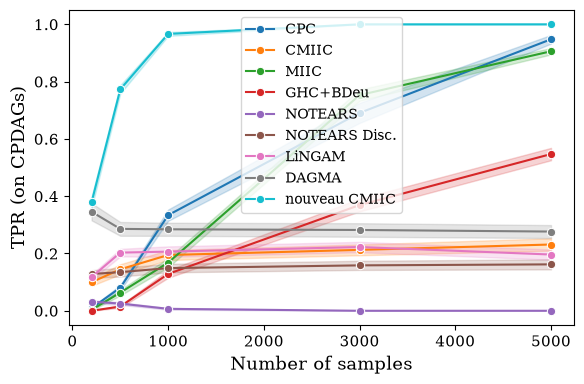

In [73]:
plot(df, 20, "TPR", "TPR (on CPDAGs)")

### Sur les squelettes

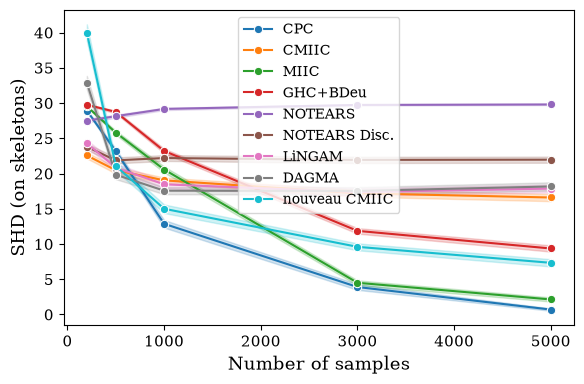

In [74]:
plot(df, 20, "SHD_skeleton", "SHD (on skeletons)")

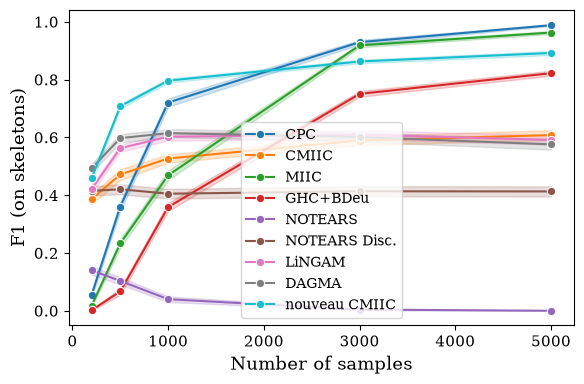

In [75]:
plot(df, 20, "F1-Score_skeleton", "F1 (on skeletons)")

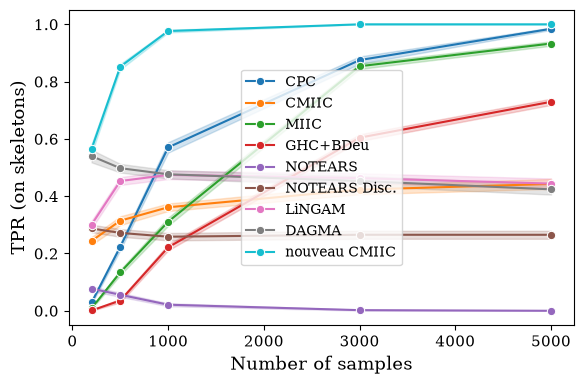

In [76]:
plot(df, 20, "TPR_skeleton", "TPR (on skeletons)")